# FlyRank Capstone — Refresh / Content Opportunity Scoring

**Research question:** Can a transparent content-review baseline and a Random Forest help rank content items for refresh review, when evaluation is performed on held-out clients?

This notebook is designed to run from the repository root or from `work/notebooks/`. It uses the prepared anonymized feature vector from the weekly work, evaluates model and baseline on the same grouped client holdout, creates a ranked review queue, generates charts, and writes a public-safe HTML research paper.

**Important:** the paper reports measured results from this run. It does not claim causal refresh impact, prove how Google ranks pages, or publish client/content identifiers.

## 1. Setup and load data

Run this notebook from the repository. It expects `data/processed/refresh_feature_vector.csv`. If the file is missing, stop and put the prepared file in that location; do not replace it with invented data.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score, f1_score,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

# Find repository root from either the root folder or work/notebooks.
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
REPO_ROOT = next(
    (p for p in candidates if (p / "data" / "processed" / "refresh_feature_vector.csv").exists()),
    Path.cwd()
)

DATA_PATH = REPO_ROOT / "data" / "processed" / "refresh_feature_vector.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH}. Run this notebook from your repo and check the data/processed folder."
    )

df = pd.read_csv(DATA_PATH)
print("Repository:", REPO_ROOT)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

required = {"client_id", "content_id", "is_declining_label"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Required columns missing from feature vector: {sorted(missing)}")

df = df.dropna(subset=["client_id", "is_declining_label"]).copy()
df["is_declining_label"] = pd.to_numeric(df["is_declining_label"], errors="coerce")
df = df.dropna(subset=["is_declining_label"]).copy()
df["is_declining_label"] = df["is_declining_label"].astype(int)

if df["is_declining_label"].nunique() < 2:
    raise ValueError("The target has only one class after cleaning; model evaluation is not valid.")

print("Rows after target cleaning:", len(df))
print("Positive label rate:", round(df["is_declining_label"].mean(), 4))

Repository: /Users/theshivrajpatil/FlyRank-ML-Internship
Dataset shape: (30000, 52)
Columns: ['content_id', 'client_id', 'search_volume', 'competition', 'competition_level', 'cpc', 'content_type', 'main_intent', 'word_count', 'char_count', 'provider_used', 'model_used', 'impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'days_with_impressions', 'days_with_sessions', 'impressions_last_30d', 'clicks_last_30d', 'sessions_last_30d', 'impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'content_age_days', 'age_tier', 'age_tier_order', 'days_since_last_update', 'freshness_tier', 'word_count_tier', 'char_count_tier', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct', 'impression_tier', 'position_tier', 'trend_direction', 'trend_pct', 'is_declining_label', 'log_impressions_90d', 'log_clicks_90d', 'log_sessions_90d', 'log_ai_sessions_90d', 'has_clicks', 'has_ai_sessions

## 2. Define the target, baseline, and honest validation split

The label is `is_declining_label` as provided in the prepared feature vector. The code excludes the target, its known source fields (`trend_direction`, `trend_pct`), and identifiers. A grouped client holdout prevents rows from the same client appearing in both training and test sets.

The baseline is a transparent weighted percentile score using staleness, search demand, and impressions where those fields exist. It is a prioritization heuristic, not a learned model. Model and baseline are compared on the same held-out rows using Precision@50 and ROC-AUC where both are calculable.

In [2]:
TARGET = "is_declining_label"
GROUP = "client_id"
ID_COL = "content_id"

forbidden = {
    TARGET, GROUP, ID_COL,
    "trend_direction", "trend_pct"
}
feature_cols = [c for c in df.columns if c not in forbidden]

# Extra name-based warning: inspect these if any appear.
warning_terms = ("label", "target", "outcome", "future", "next_period", "post", "after")
suspicious = [c for c in feature_cols if any(t in c.lower() for t in warning_terms)]
print("Potentially suspicious feature names to inspect:", suspicious)
print("Candidate features:", len(feature_cols))

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(
    splitter.split(df[feature_cols], df[TARGET], groups=df[GROUP])
)
train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

client_overlap = set(train_df[GROUP]).intersection(set(test_df[GROUP]))
assert not client_overlap, f"Client leakage detected: {len(client_overlap)} overlapping clients"

X_train, y_train = train_df[feature_cols].copy(), train_df[TARGET].copy()
X_test, y_test = test_df[feature_cols].copy(), test_df[TARGET].copy()

numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=True)

transformers = []
if numeric_features:
    transformers.append(("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), numeric_features))
if categorical_features:
    transformers.append(("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", one_hot)
    ]), categorical_features))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250,
        max_depth=10,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
model_score = model.predict_proba(X_test)[:, 1]

print("Train rows:", len(train_df), "| Test rows:", len(test_df))
print("Train clients:", train_df[GROUP].nunique(), "| Test clients:", test_df[GROUP].nunique())
print("Client overlap:", len(client_overlap))

Potentially suspicious feature names to inspect: []
Candidate features: 47
Train rows: 23837 | Test rows: 6163
Train clients: 25 | Test clients: 7
Client overlap: 0


## 3. Compare model with the baseline on the same test set

In [3]:
def percentile_score(series):
    values = pd.to_numeric(series, errors="coerce")
    return values.rank(pct=True).fillna(0)

# Transparent baseline score, computed from available pre-outcome signals.
baseline_components = []
if "days_since_last_update" in test_df.columns:
    baseline_components.append(("staleness", "days_since_last_update", 0.50))
if "search_volume" in test_df.columns:
    baseline_components.append(("demand", "search_volume", 0.30))
if "impressions_90d" in test_df.columns:
    baseline_components.append(("impressions", "impressions_90d", 0.20))

if not baseline_components:
    raise ValueError(
        "No baseline inputs found. Expected at least one of days_since_last_update, search_volume, impressions_90d."
    )

weights_total = sum(item[2] for item in baseline_components)
baseline_score = np.zeros(len(test_df), dtype=float)
for _, col, weight in baseline_components:
    baseline_score += (weight / weights_total) * percentile_score(test_df[col]).to_numpy()

def precision_at_k(y_true, scores, k=50):
    y_arr = np.asarray(y_true)
    score_arr = np.asarray(scores)
    k = min(k, len(y_arr))
    if k == 0:
        return float("nan")
    idx = np.argsort(-score_arr)[:k]
    return float(y_arr[idx].mean())

def safe_auc(y_true, scores):
    if pd.Series(y_true).nunique() < 2:
        return float("nan")
    return float(roc_auc_score(y_true, scores))

model_p50 = precision_at_k(y_test, model_score, 50)
baseline_p50 = precision_at_k(y_test, baseline_score, 50)
model_auc = safe_auc(y_test, model_score)
baseline_auc = safe_auc(y_test, baseline_score)

model_pred = (model_score >= 0.5).astype(int)
metrics = pd.DataFrame([
    {
        "method": "Transparent baseline",
        "precision_at_50": baseline_p50,
        "roc_auc": baseline_auc,
        "precision_at_0.5": precision_score(y_test, (baseline_score >= 0.5).astype(int), zero_division=0),
        "recall_at_0.5": recall_score(y_test, (baseline_score >= 0.5).astype(int), zero_division=0),
        "f1_at_0.5": f1_score(y_test, (baseline_score >= 0.5).astype(int), zero_division=0),
    },
    {
        "method": "Random Forest",
        "precision_at_50": model_p50,
        "roc_auc": model_auc,
        "precision_at_0.5": precision_score(y_test, model_pred, zero_division=0),
        "recall_at_0.5": recall_score(y_test, model_pred, zero_division=0),
        "f1_at_0.5": f1_score(y_test, model_pred, zero_division=0),
    }
])
display(metrics.round(4))
metrics.to_csv(REPO_ROOT / "work" / "outputs" / "capstone_metrics.csv", index=False) if (REPO_ROOT / "work" / "outputs").exists() else None

print("Precision@50 difference (model - baseline):", round(model_p50 - baseline_p50, 4))
print("ROC-AUC difference (model - baseline):", round(model_auc - baseline_auc, 4) if np.isfinite(model_auc) and np.isfinite(baseline_auc) else "not available")

,method,precision_at_50,roc_auc,precision_at_0.5,recall_at_0.5,f1_at_0.5
0,Transparent baseline,0.40,0.4499,0.4596,0.4081,0.4323
1,Random Forest,0.92,0.7886,0.6872,0.7660,0.7244


Precision@50 difference (model - baseline): 0.52
ROC-AUC difference (model - baseline): 0.3387


## 4. Create a ranked review queue

The queue is a decision-support artifact. It contains anonymous row-level identifiers for internal review; the public paper only publishes aggregate results and does not embed this queue or client/content IDs.

In [4]:
# Score all rows for a practical review queue.
all_scores = model.predict_proba(df[feature_cols])[:, 1]
queue = df[[ID_COL]].copy()
queue["model_score"] = all_scores

# Reason codes use observed signals only.
reason_conditions = []
reason_choices = []
if "days_since_last_update" in df.columns:
    stale_cutoff = pd.to_numeric(df["days_since_last_update"], errors="coerce").quantile(0.75)
    reason_conditions.append(pd.to_numeric(df["days_since_last_update"], errors="coerce") >= stale_cutoff)
    reason_choices.append("STALE_CONTENT")
if "search_volume" in df.columns:
    demand_cutoff = pd.to_numeric(df["search_volume"], errors="coerce").quantile(0.75)
    reason_conditions.append(pd.to_numeric(df["search_volume"], errors="coerce") >= demand_cutoff)
    reason_choices.append("HIGH_SEARCH_DEMAND")

if reason_conditions:
    queue["reason_code"] = np.select(reason_conditions, reason_choices, default="GENERAL_REVIEW")
else:
    queue["reason_code"] = "MODEL_SCORE_REVIEW"

queue["action"] = np.select(
    [queue["model_score"] >= queue["model_score"].quantile(0.75),
     queue["model_score"] >= queue["model_score"].quantile(0.40)],
    ["HIGH_PRIORITY", "REVIEW"],
    default="MONITOR"
)
queue = queue.sort_values("model_score", ascending=False).reset_index(drop=True)
queue.insert(0, "rank", np.arange(1, len(queue) + 1))

output_dir = REPO_ROOT / "work" / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)
queue.to_csv(output_dir / "capstone_ranked_review_queue.csv", index=False)

print("Rows ranked:", len(queue))
print("Action counts:")
display(queue["action"].value_counts().rename_axis("action").reset_index(name="rows"))
print("Internal top 10 review queue (do not publish):")
display(queue.head(10))

Rows ranked: 30000
Action counts:


,action,rows
0,MONITOR,12000
1,REVIEW,10500
2,HIGH_PRIORITY,7500


Internal top 10 review queue (do not publish):


,rank,content_id,model_score,reason_code,action
0,1,content_875fc7912e9b,0.946639,GENERAL_REVIEW,HIGH_PRIORITY
1,2,content_4bcb30ab7531,0.936900,GENERAL_REVIEW,HIGH_PRIORITY
2,3,content_d88a80933ba2,0.931278,GENERAL_REVIEW,HIGH_PRIORITY
3,4,content_252c884e4400,0.929627,GENERAL_REVIEW,HIGH_PRIORITY
4,5,content_20e4b9f7f65e,0.927367,GENERAL_REVIEW,HIGH_PRIORITY
5,6,content_cddd5aa6c5be,0.922178,GENERAL_REVIEW,HIGH_PRIORITY
6,7,content_3585f0ab30e6,0.919021,GENERAL_REVIEW,HIGH_PRIORITY
7,8,content_4521b26bd5ff,0.918100,GENERAL_REVIEW,HIGH_PRIORITY
8,9,content_ab82c4705992,0.916298,GENERAL_REVIEW,HIGH_PRIORITY
9,10,content_5f2abb891cc6,0.916084,GENERAL_REVIEW,HIGH_PRIORITY


## 5. Charts and paper artifacts

The figures show aggregate evaluation only. They do not include client names, content identifiers, domains, URLs, private queries, or raw exports.

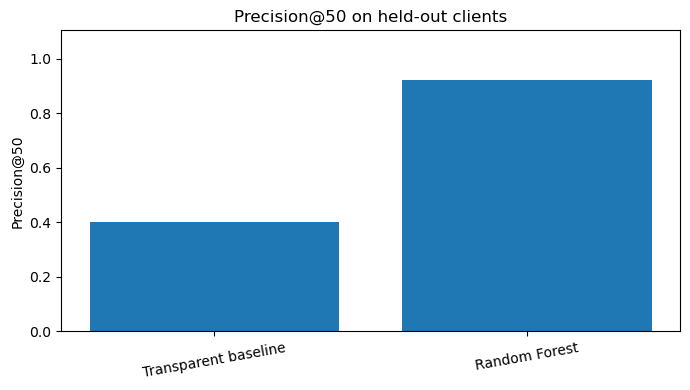

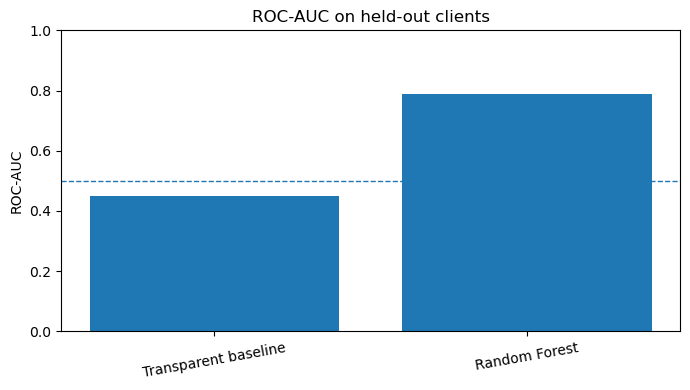

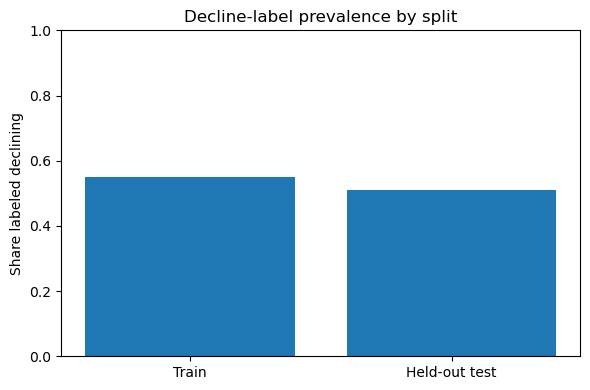

Charts written to: /Users/theshivrajpatil/FlyRank-ML-Internship/docs


In [5]:
paper_dir = REPO_ROOT / "docs"
paper_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)

# Chart 1: Precision@50 comparison
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(metrics["method"], metrics["precision_at_50"])
ax.set_title("Precision@50 on held-out clients")
ax.set_ylabel("Precision@50")
ax.set_ylim(0, max(0.05, float(metrics["precision_at_50"].max()) * 1.2))
ax.tick_params(axis="x", rotation=10)
fig.tight_layout()
p50_chart = paper_dir / "precision_at_50.png"
fig.savefig(p50_chart, dpi=160)
plt.show()
plt.close(fig)

# Chart 2: ROC-AUC comparison
auc_metrics = metrics.dropna(subset=["roc_auc"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(auc_metrics["method"], auc_metrics["roc_auc"])
ax.axhline(0.5, linestyle="--", linewidth=1)
ax.set_title("ROC-AUC on held-out clients")
ax.set_ylabel("ROC-AUC")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=10)
fig.tight_layout()
auc_chart = paper_dir / "roc_auc.png"
fig.savefig(auc_chart, dpi=160)
plt.show()
plt.close(fig)

# Chart 3: label prevalence in train vs test
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Train", "Held-out test"], [y_train.mean(), y_test.mean()])
ax.set_title("Decline-label prevalence by split")
ax.set_ylabel("Share labeled declining")
ax.set_ylim(0, 1)
fig.tight_layout()
split_chart = paper_dir / "label_prevalence.png"
fig.savefig(split_chart, dpi=160)
plt.show()
plt.close(fig)

metrics.to_csv(output_dir / "capstone_metrics.csv", index=False)
print("Charts written to:", paper_dir)

## 6. Generate the public-safe research paper

This creates `docs/index.html` for GitHub Pages. The HTML reports the measured metrics from this run and uses careful decision-support language. Review the generated page before publishing.

In [6]:
def fmt_num(value, digits=3):
    return "not available" if pd.isna(value) else f"{value:.{digits}f}"

p50_delta = model_p50 - baseline_p50
auc_delta = model_auc - baseline_auc if np.isfinite(model_auc) and np.isfinite(baseline_auc) else np.nan

if p50_delta > 0:
    result_summary = "The Random Forest ranked more positive examples in the top 50 than the transparent baseline on this held-out split."
elif p50_delta < 0:
    result_summary = "The transparent baseline ranked more positive examples in the top 50 than the Random Forest on this held-out split."
else:
    result_summary = "The two methods had equal Precision@50 on this held-out split."

if np.isfinite(auc_delta):
    auc_summary = (
        "The Random Forest had higher ROC-AUC than the baseline."
        if auc_delta > 0 else
        "The baseline had higher ROC-AUC than the Random Forest."
        if auc_delta < 0 else
        "The methods had equal ROC-AUC."
    )
else:
    auc_summary = "ROC-AUC comparison was unavailable because the test labels did not contain both classes."

feature_list = ", ".join(feature_cols[:18]) + (" …" if len(feature_cols) > 18 else "")
split_text = (
    f"{len(train_df):,} training rows across {train_df[GROUP].nunique():,} clients and "
    f"{len(test_df):,} held-out rows across {test_df[GROUP].nunique():,} clients. "
    f"Client overlap was {len(client_overlap)}."
)

html = f'''<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Refresh Opportunity Scoring | FlyRank Search Intelligence Capstone</title>
<style>
:root {{ --ink:#182230; --muted:#586579; --line:#dbe2ea; --panel:#f5f7fa; --accent:#175cd3; }}
* {{ box-sizing:border-box; }}
body {{ margin:0; font-family:Inter,system-ui,-apple-system,Segoe UI,Arial,sans-serif; color:var(--ink); line-height:1.65; background:#fff; }}
header {{ background:#101828; color:#fff; padding:56px 22px; }}
header .wrap, main {{ max-width:980px; margin:auto; }}
.eyebrow {{ text-transform:uppercase; letter-spacing:.12em; font-size:.78rem; color:#b2ccff; font-weight:700; }}
h1 {{ font-size:clamp(2rem,5vw,3.5rem); line-height:1.1; margin:.5rem 0 1rem; }}
header p {{ max-width:780px; color:#e4e7ec; font-size:1.1rem; }}
main {{ padding:24px 22px 70px; }}
section {{ padding:24px 0; border-bottom:1px solid var(--line); }}
h2 {{ margin:0 0 12px; font-size:1.55rem; }}
h3 {{ margin-bottom:6px; }}
.muted {{ color:var(--muted); }}
.cards {{ display:grid; grid-template-columns:repeat(auto-fit,minmax(180px,1fr)); gap:12px; margin:20px 0; }}
.card {{ background:var(--panel); border:1px solid var(--line); border-radius:12px; padding:16px; }}
.card strong {{ display:block; font-size:1.7rem; }}
figure {{ margin:22px 0; }}
figure img {{ display:block; width:100%; max-width:760px; height:auto; border:1px solid var(--line); border-radius:10px; }}
figcaption {{ color:var(--muted); font-size:.9rem; }}
table {{ border-collapse:collapse; width:100%; margin:16px 0; }}
th,td {{ padding:10px 12px; border-bottom:1px solid var(--line); text-align:left; }}
th {{ background:var(--panel); }}
.callout {{ background:#eff8ff; border-left:4px solid var(--accent); padding:14px 18px; border-radius:6px; }}
footer {{ color:var(--muted); font-size:.9rem; padding-top:28px; }}
a {{ color:var(--accent); }}
@media(max-width:600px) {{ header {{ padding:38px 18px; }} main {{ padding:16px 18px 50px; }} }}
</style>
</head>
<body>
<header><div class="wrap">
<div class="eyebrow">Search Intelligence Capstone · FlyRank ML Internship dataset</div>
<h1>Refresh Opportunity Scoring for Content Review</h1>
<p>A practical evaluation of whether a transparent heuristic or a Random Forest can help prioritize content items for human refresh review.</p>
<p class="muted">Research report · Reproducible notebook-based analysis</p>
</div></header>
<main>
<section>
<h2>Abstract</h2>
<p>This project asks whether available content and search-performance signals can help rank items for refresh review. It uses the prepared anonymized FlyRank feature vector and compares a transparent percentile-weighted baseline with a Random Forest. Evaluation uses a grouped client holdout so that clients in the test set are not present in training. On this run, baseline Precision@50 was <strong>{fmt_num(baseline_p50)}</strong> and Random Forest Precision@50 was <strong>{fmt_num(model_p50)}</strong>; ROC-AUC was {fmt_num(baseline_auc)} for the baseline and {fmt_num(model_auc)} for the model. The results support only dataset-specific prioritization and do not establish that refreshing a page causes improved search performance.</p>
</section>
<section>
<h2>1. Introduction and problem statement</h2>
<p>Content teams have limited time for manual review. The decision supported here is which items should be inspected first, not which pages should automatically be changed. A ranked queue can make review more consistent, but its usefulness depends on whether it performs better than a simple, explainable rule and whether the evaluation avoids leakage.</p>
</section>
<section>
<h2>2. Data</h2>
<p>The analysis uses the prepared, anonymized feature vector at <code>data/processed/refresh_feature_vector.csv</code> from the repository's FlyRank ML Internship workflow. The target is the supplied <code>is_declining_label</code>. The notebook reports row and client counts at run time. It excludes client and content identifiers from model inputs, and excludes <code>trend_direction</code> and <code>trend_pct</code> because they are label-related fields. No client names, domains, URLs, private queries, credentials, or raw row-level exports are included in this paper.</p>
<div class="cards">
<div class="card"><span class="muted">Rows used</span><strong>{len(df):,}</strong></div>
<div class="card"><span class="muted">Candidate features</span><strong>{len(feature_cols)}</strong></div>
<div class="card"><span class="muted">Decline-label share</span><strong>{df[TARGET].mean():.1%}</strong></div>
<div class="card"><span class="muted">Client overlap</span><strong>{len(client_overlap)}</strong></div>
</div>
<p><strong>Feature examples:</strong> {feature_list}.</p>
<p class="muted">The exact release identifier and source date window should be stated only after confirming them against the dataset card and warehouse export used for this run. Do not infer a date range from file names alone.</p>
</section>
<section>
<h2>3. Methodology</h2>
<h3>Label and assumptions</h3>
<p>The task is framed as ranking items associated with the supplied decline label. The label is treated as an observed dataset outcome, not a future outcome unless the source definition explicitly establishes that temporal relationship.</p>
<h3>Baseline</h3>
<p>The transparent baseline combines percentile ranks of available staleness, search-demand, and impression signals with weights 0.50, 0.30, and 0.20 respectively; weights are renormalized if a component is unavailable. This is a heuristic prioritization score, not a trained predictor.</p>
<h3>Model and validation</h3>
<p>A Random Forest with 250 trees, maximum depth 10, minimum leaf size 10, class weighting, and a fixed random seed is compared with the baseline. The split holds out 20% of client groups. Numeric values are median-imputed; categorical values are imputed with the most frequent category and one-hot encoded. The same held-out rows are used for both methods.</p>
<p><strong>Leakage checks:</strong> target, identifiers, <code>trend_direction</code>, and <code>trend_pct</code> are excluded. Potentially suspicious feature names are printed for manual review. The split assertion verifies zero client overlap.</p>
</section>
<section>
<h2>4. Results</h2>
<p>{result_summary} {auc_summary}</p>
<table><thead><tr><th>Method</th><th>Precision@50</th><th>ROC-AUC</th><th>Precision at 0.5</th><th>Recall at 0.5</th><th>F1 at 0.5</th></tr></thead><tbody>
<tr><td>Transparent baseline</td><td>{fmt_num(baseline_p50)}</td><td>{fmt_num(baseline_auc)}</td><td>{fmt_num(metrics.iloc[0]['precision_at_0.5'])}</td><td>{fmt_num(metrics.iloc[0]['recall_at_0.5'])}</td><td>{fmt_num(metrics.iloc[0]['f1_at_0.5'])}</td></tr>
<tr><td>Random Forest</td><td>{fmt_num(model_p50)}</td><td>{fmt_num(model_auc)}</td><td>{fmt_num(metrics.iloc[1]['precision_at_0.5'])}</td><td>{fmt_num(metrics.iloc[1]['recall_at_0.5'])}</td><td>{fmt_num(metrics.iloc[1]['f1_at_0.5'])}</td></tr>
</tbody></table>
<figure><img src="precision_at_50.png" alt="Precision at 50 comparison"><figcaption>Figure 1. Precision@50 on the held-out client set. Higher is better for a top-50 review queue.</figcaption></figure>
<figure><img src="roc_auc.png" alt="ROC-AUC comparison"><figcaption>Figure 2. ROC-AUC on the same held-out client set. The dashed line marks chance-level discrimination.</figcaption></figure>
<figure><img src="label_prevalence.png" alt="Label prevalence in train and test"><figcaption>Figure 3. Label prevalence in the training and held-out test partitions.</figcaption></figure>
<p><strong>Split details:</strong> {split_text}</p>
</section>
<section>
<h2>5. Limitations and honest framing</h2>
<ul>
<li>The label's meaning and time horizon are inherited from the prepared feature vector. If it is derived from a contemporaneous trend field, the experiment should be described as label ranking/classification, not forecasting future decline.</li>
<li>A single grouped split can be sensitive to which clients are held out. Repeated group splits or a time-aware evaluation would strengthen the evidence.</li>
<li>Precision@50 depends on the test-set size and positive-label prevalence. Results should be interpreted alongside the baseline and label rate.</li>
<li>Associations in this dataset do not show that refreshing content will cause clicks, impressions, or rankings to improve.</li>
<li>This project does not reveal or prove Google's ranking algorithm and does not guarantee generalization to all sites or industries.</li>
</ul>
<div class="callout"><strong>Interpretation:</strong> Treat the ranking as decision-support for human review. Do not automatically publish, delete, merge, or rewrite content based on a score alone.</div>
</section>
<section>
<h2>6. Ranked recommendations and action playbook</h2>
<ol>
<li><strong>HIGH PRIORITY — inspect first:</strong> review high-ranked items, confirm the search need is still relevant, and check for technical/indexing issues before editing.</li>
<li><strong>REVIEW — validate the opportunity:</strong> check recent impressions, clicks, CTR, position, engagement, and whether the page has already been updated.</li>
<li><strong>MONITOR — avoid unnecessary edits:</strong> retain items with weak or ambiguous signals and re-check them when newer data becomes available.</li>
</ol>
<p>Reason codes in the internal queue include <code>STALE_CONTENT</code>, <code>HIGH_SEARCH_DEMAND</code>, and <code>GENERAL_REVIEW</code> where the relevant input fields exist. The full queue is kept in the repository output folder for internal analysis and is not embedded in this public paper.</p>
</section>
<section>
<h2>7. Reproducibility</h2>
<ul>
<li>Notebook: <code>work/notebooks/capstone.ipynb</code> (commit this notebook after running it).</li>
<li>Metrics: <code>work/outputs/capstone_metrics.csv</code>.</li>
<li>Ranked queue: <code>work/outputs/capstone_ranked_review_queue.csv</code> (internal artifact; do not publish raw identifiers).</li>
<li>Charts: <code>docs/precision_at_50.png</code>, <code>docs/roc_auc.png</code>, and <code>docs/label_prevalence.png</code>.</li>
</ul>
<p>To reproduce, install the repository requirements, run this notebook top-to-bottom, inspect the leakage warnings, and review the generated HTML before deployment.</p>
</section>
<section>
<h2>8. Acknowledgments and data credit</h2>
<p>Built on the <a href="https://flyrank.ai" rel="noopener noreferrer">FlyRank ML Internship dataset</a>. Thanks to the dataset and internship team for providing an anonymized basis for this educational analysis.</p>
</section>
<footer>
<p>Generated from the capstone notebook. Metrics are specific to this dataset version, feature construction, split, and random seed. This report is research decision-support, not a causal study.</p>
</footer>
</main></body></html>'''

(paper_dir / "index.html").write_text(html, encoding="utf-8")
print("Paper written:", paper_dir / "index.html")
print("Next: inspect docs/index.html, then publish the docs folder with GitHub Pages.")

Paper written: /Users/theshivrajpatil/FlyRank-ML-Internship/docs/index.html
Next: inspect docs/index.html, then publish the docs folder with GitHub Pages.


## 7. Final checks before publishing

- Confirm the notebook ran from the first cell to the last without errors.
- Check that the HTML metrics match the displayed table.
- Confirm the dataset release/date window from the source card before adding it to the paper.
- Inspect `docs/index.html` for accidental identifiers or private information.
- Commit the notebook, charts, and HTML paper.
- Enable GitHub Pages from the repository's `docs/` folder on the `main` branch.
- Put the exact live paper URL as the only line in `submission/paper_url.txt`.